In [3]:
import os
import pandas as pd
import numpy as np
os.chdir("C://kurssit/Dippatyo/tutkielma/soccer_hmm_project")
from src.dataset import make_data_dict
from src.dataset import concatenate_dfs
import matplotlib.pyplot as plt
from scipy.stats import vonmises
from scipy.signal import butter, filtfilt
import matplotlib

2026-04-04 01:56:41.603 | INFO     | src.config:<module>:11 - PROJ_ROOT path is: C:\kurssit\Dippatyo\tutkielma\soccer_hmm_project


In [ ]:
dd = make_data_dict(directory="data/raw/Catapult_RAW", preprocess_data=True)

2026-03-22 22:18:22.952 | INFO     | src.dataset:make_data_dict:876 - Processing file Game_1_hyökkääjä_JM_Catapult-Export-1770541727119.csv...
15
                 x            y        speed   playerload    accelrate
count  3460.000000  3460.000000  3460.000000  3460.000000  3460.000000
mean     -8.914781    -3.969212     0.857711     0.258734     1.167917
std       6.650807    22.256829     1.299173     0.401479     1.771706
min     -30.037324   -52.682586     0.000000     0.003219     0.009574
25%     -11.377774   -24.432503     0.000000     0.010442     0.037766
50%     -10.619256   -18.477081     0.000000     0.013226     0.060999
75%      -3.565036    16.339237     1.470873     0.326199     1.635831
max      11.112293    57.416383     8.722292     2.135970     9.643891
Setting start to NaN until index 126
Setting end to NaN from index 1453
Idle periods: 1
Removed idle period from 2025-08-20 20:16:38 to 2025-08-20 20:23:04 lasting 6.43 minutes.
2026-03-22 22:18:23.154 | INFO   

In [ ]:
def preprocess2(input_df):

    df = input_df.copy()

    col_renames = dict({
        "Excel Timestamp": "timestamp",
        "Latitude": "lat",
        "Longitude": "lon",
        "Speed": "speed",
        "Accel X": "acc_x",
        "Accel Y": "acc_y",
        "Accel Z": "acc_z"
    })

    df.columns = df.columns.str.strip()
    #df.drop(columns=["Heart Rate"], axis=1, inplace=True)
    df.rename(columns=col_renames, inplace=True)

    #parse time, sort index
    df["timestamp"] = pd.to_datetime('1899-12-30') + pd.to_timedelta(df["timestamp"], unit="D")
    df = df.sort_values("timestamp")
    df = df.set_index("timestamp")
    df.index = df.index.round("100ms")

    #reindex to exact 10 Hz
    full_index = pd.date_range(
        start=df.index.min(),
        end=df.index.max(),
        freq=f"{int(100)}ms"
    )

    df = df.reindex(full_index)
    df.reset_index(names="timestamp", inplace=True)

    mask = df["speed"].isna()

    groups = mask.ne(mask.shift()).cumsum()

    df["nan_segment"] = groups.where(mask)

    df["nan_length"] = df.groupby("nan_segment")["speed"].transform("size")

    #convert lat/lon to local meters
    R = 6371000  # Earth radius (m)

    lat_rad = np.deg2rad(df["lat"])
    lon_rad = np.deg2rad(df["lon"])

    lat0 = lat_rad.iloc[0]
    lon0 = lon_rad.iloc[0]
    
    #local equirectangular projection
    df["x"] = R * (lon_rad - lon0) * np.cos(lat0)
    df["y"] = R * (lat_rad - lat0)

    # interpolate only short gaps (limit=1 means max 1 consecutive NaN)
    #df[["acc_x", "acc_y", "acc_z"]] = (
    #    df[["acc_x", "acc_y", "acc_z"]]
    #      .interpolate(method="linear", limit=1)
    #)

    # interpolate only short gaps (limit=1 means max 1 consecutive NaN)
    df[["acc_x", "acc_y", "acc_z", "speed", "x", "y"]] = (
        df[["acc_x", "acc_y", "acc_z", "speed", "x", "y"]]
          .interpolate(method="linear", limit_direction="both", limit=1)
    )

        # Compute gravity-removed Accel'Rate
    df["acc_mag_raw"] = np.sqrt(
        df["acc_x"]**2 +
        df["acc_y"]**2 +
        df["acc_z"]**2
    )

    df["ar_10hz_raw"] = np.abs(np.diff(df["acc_mag_raw"], prepend=df["acc_mag_raw"].iloc[0]))

    # --- Apply high-pass filter per continuous valid segment ---

    acc_cols = ["acc_x", "acc_y", "acc_z"]
    lowcut = 0.1  # Hz (reasonable for gravity removal at 10 Hz)

    # Create mask of rows where all acceleration channels are present
    valid_mask = df[acc_cols].notna().all(axis=1)

    valid_groups = (valid_mask & ~valid_mask.shift(fill_value=False)).cumsum()
    df["segment_id"] = valid_groups.where(valid_mask)

    # Prepare output columns
    for col in acc_cols:
        df[f"{col}_filt"] = np.nan

    # Filtering parameters
    fs = 10
    lowcut = 0.1
    nyq = fs / 2
    low = lowcut / nyq
    b, a = butter(4, low, btype="highpass")

    padlen = 3 * max(len(a), len(b))
    print(padlen)

    for seg in df[valid_mask].groupby("segment_id"):
        idx = seg[1].index
        segment_length = len(idx)

        if segment_length >= padlen:

            for col in acc_cols:
                try:
                    filtered = filtfilt(b, a, df.loc[idx, col].values)
                    df.loc[idx, f"{col}_filt"] = filtered
                except Exception:
                    # in case filtfilt fails for numerical reasons
                    continue

    # Compute gravity-removed Accel'Rate
    df["acc_mag_filt"] = np.sqrt(
        df["acc_x_filt"]**2 +
        df["acc_y_filt"]**2 +
        df["acc_z_filt"]**2
    )

    df["ar_10hz_filt"] = np.abs(np.diff(df["acc_mag_filt"], prepend=df["acc_mag_filt"].iloc[0]))

    df["second"] = df["timestamp"].dt.floor("s")
        # Compute gravity-removed Accel'Rate
    
    df["diff_ar"] = df["ar_10hz_raw"] - df["ar_10hz_filt"]
    df["diff_x"] = df["acc_x"] - df["acc_x_filt"]
    df["diff_y"] = df["acc_y"] - df["acc_y_filt"]
    df["diff_z"] = df["acc_z"] - df["acc_z_filt"]

    return df

In [ ]:
mean = 0

for key in dd.keys():
    mean += dd[key].shape[0]*2/60
    print("Length: ", dd[key].shape[0]*2/60)

Length:  37.8
Length:  92.23333333333333
Length:  89.06666666666666
Length:  97.36666666666666
Length:  96.1
Length:  77.83333333333333
Length:  31.266666666666666
Length:  93.53333333333333
Length:  56.233333333333334
Length:  90.16666666666667
Length:  81.9
Length:  83.53333333333333
Length:  70.13333333333334
Length:  34.266666666666666
Length:  63.733333333333334
Length:  88.6
Length:  96.03333333333333
Length:  64.03333333333333
Length:  26.066666666666666
Length:  83.0
Length:  81.0
Length:  95.03333333333333
Length:  71.6
Length:  97.8
Length:  100.2
Length:  71.96666666666667
Length:  94.1
Length:  83.66666666666667
Length:  87.83333333333333
Length:  42.06666666666667
Length:  92.56666666666666
Length:  95.3
Length:  94.3
Length:  81.0
Length:  95.0
Length:  77.5
Length:  62.13333333333333
Length:  85.63333333333334
Length:  91.7
Length:  93.43333333333334
Length:  60.6
Length:  65.76666666666667


In [ ]:
summary = pd.read_csv("data/summary/summarydata.csv")

In [ ]:
summary[summary["Split Name"] == "game"]

,Team,Match,Player,Position,Split Name,Tags,Split Start Time,Split End Time,Duration,Distance (km),...,Deceleration Zone Count: 0 - 1 m/s/s,Deceleration Zone Count: 1 - 2 m/s/s,Deceleration Zone Count: 2 - 3 m/s/s,Deceleration Zone Count: 3 - 4 m/s/s,Deceleration Zone Count: > 4 m/s/s,Zone 1,Zone 2,Zone 3,Zone 4,Zone 5
0,Joukkue 1,ottelu 1,nimi 1,Hyökkääjä,game,game,45793.83329,45793.90892,4135,7.6674,...,0,147,66,31,20,7.1012,0.2603,0.2061,0.0947,0.0051
3,Joukkue 1,ottelu 2,nimi 1,Hyökkääjä,game,game,45889.83338,45889.90989,1899,3.8293,...,0,66,61,13,22,3.5666,0.1694,0.0779,0.0155,0.0000
6,Joukkue 1,ottelu 3,nimi 1,Hyökkääjä,game,game,45798.83335,45798.91034,3450,6.9300,...,0,115,70,40,26,6.1145,0.3290,0.3385,0.1395,0.0085
9,Joukkue 1,ottelu 4,nimi 1,Hyökkääjä,game,game,45924.83334,45924.90662,561,1.1447,...,0,18,12,4,5,1.0160,0.0637,0.0569,0.0081,0.0000
12,Joukkue 1,ottelu 5,nimi 1,Hyökkääjä,game,game,45910.83334,45910.90980,4874,9.2056,...,0,151,110,54,35,8.3749,0.3880,0.3040,0.1275,0.0111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1266,Joukkue 1,ottelu 3,nimi 9,Puolustaja,game,game,45798.83335,45798.91034,5756,9.4046,...,0,196,146,46,36,8.7126,0.3211,0.2494,0.1130,0.0084
1269,Joukkue 2,ottelu 13,nimi 9,Puolustaja,game,game,45802.77089,45802.84586,5656,9.7426,...,0,253,169,75,48,9.2364,0.3387,0.1381,0.0293,0.0000
1272,Joukkue 2,ottelu 14,nimi 9,Puolustaja,game,game,45850.70831,45850.78917,757,1.1737,...,0,36,19,5,5,1.1041,0.0485,0.0212,0.0000,0.0000
1275,Joukkue 1,ottelu 22,nimi 9,Puolustaja,game,game,45883.84375,45883.92041,5761,9.8646,...,0,226,126,61,53,9.0197,0.3764,0.3889,0.0770,0.0026


In [ ]:
print(mean/len(dd))

77.93095238095236


In [ ]:
df = concatenate_dfs(dd)

In [ ]:
df.groupby(["player", "track_id"])["timestamp"].count()*2/60

player  track_id
AA      4            96.100000
        23           97.800000
        41           65.766667
AY      25           71.966667
BP      15           88.600000
EB      12           70.133333
        18           26.066667
        34           95.000000
EP      10           81.900000
        22           71.600000
        30           92.566667
ET      13           34.266667
JM      0            37.800000
JN      5            77.833333
KL      21           95.033333
LT      9            90.166667
        36           62.133333
ML      20           81.000000
        27           83.666667
NN      1            92.233333
NR      7            93.533333
        28           87.833333
OG      11           83.533333
        19           83.000000
        26           94.100000
        39           93.433333
OH      14           63.733333
        29           42.066667
        35           77.500000
OK      24          100.200000
        33           81.000000
        38           9

In [ ]:
df["player"].unique()

array(['JM', 'NN', 'SS', 'ST', 'AA', 'JN', 'RM', 'NR', 'LT', 'EP', 'OG',
       'EB', 'ET', 'OH', 'BP', 'OS', 'ML', 'KL', 'OK', 'AY', 'PB', 'OKe',
       'OKes'], dtype=object)

In [ ]:
df["game"].unique()

array(['1', '2', '3', '4', '5', '6'], dtype=object)

In [ ]:
import seaborn as sns

15


<Axes: >

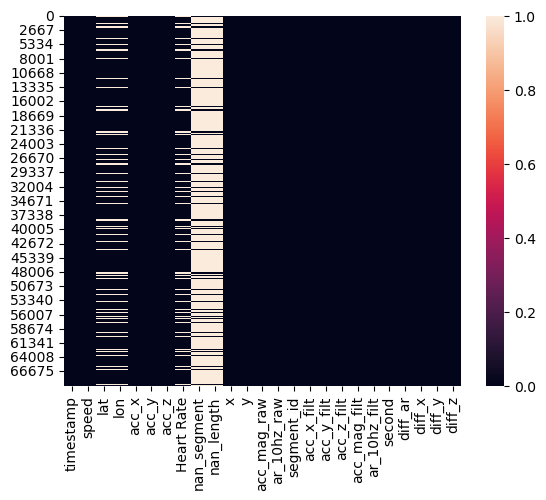

In [ ]:
df = dd[23]

p_df = preprocess2(df)
sns.heatmap(p_df.isna())

In [ ]:
p_df["nan_length"].describe()

count    9519.000000
mean        1.202962
std         1.846661
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        28.000000
Name: nan_length, dtype: float64

In [ ]:
df1 = preprocess2(dd[27])
df1["acc_mag_filt"].describe()

15


count    67798.000000
mean         0.348006
std          0.321364
min          0.000833
25%          0.151066
50%          0.233917
75%          0.416690
max          3.644241
Name: acc_mag_filt, dtype: float64

In [ ]:
df1["acc_mag_raw"].describe()

count    67848.000000
mean         0.988152
std          0.363257
min          0.021736
25%          0.853244
50%          0.938291
75%          1.062188
max          4.511531
Name: acc_mag_raw, dtype: float64

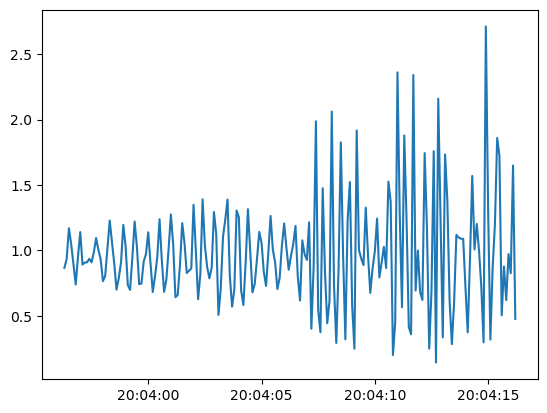

In [ ]:
plt.plot("timestamp", "acc_mag_raw", data=p_df[4000:4200])

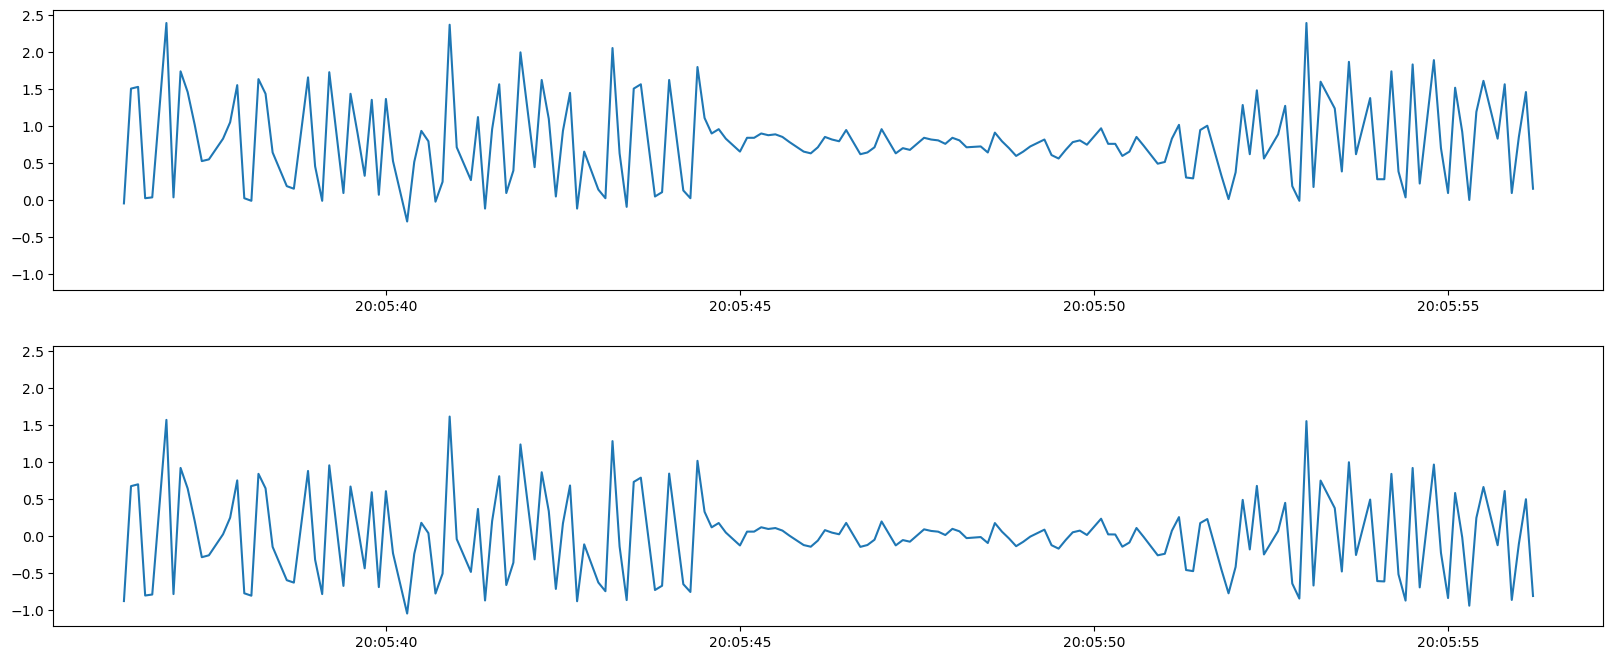

In [ ]:
fig, axs = plt.subplots(2,1, figsize=(20,8), sharey=True)

data = p_df[5000:5200]

axs[0].plot("timestamp", "acc_x", data=data)
axs[1].plot("timestamp", "acc_x_filt", data=data)

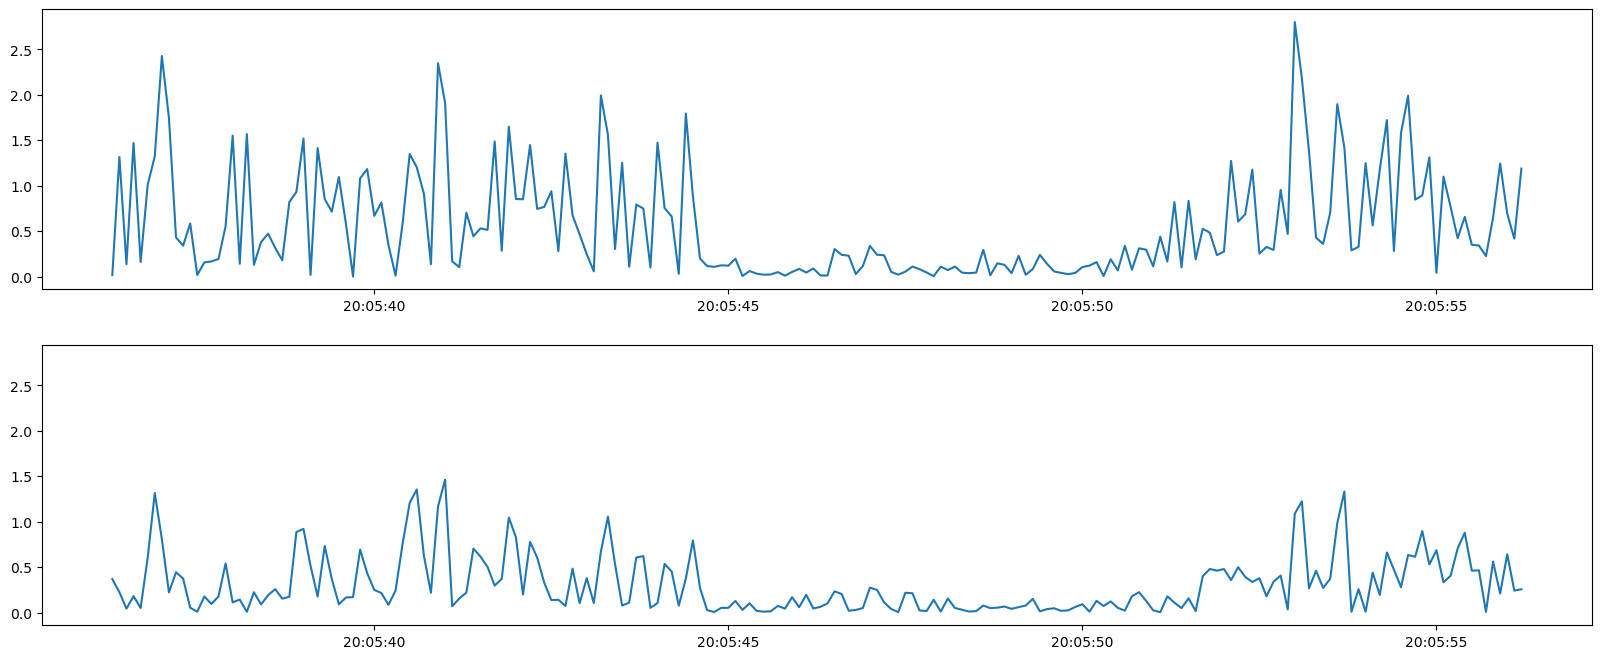

In [ ]:
fig, axs = plt.subplots(2,1, figsize=(20,8), sharey=True)

data = p_df[5000:5200]

axs[0].plot("timestamp", "ar_10hz_raw", data=data)
axs[1].plot("timestamp", "ar_10hz_filt", data=data)

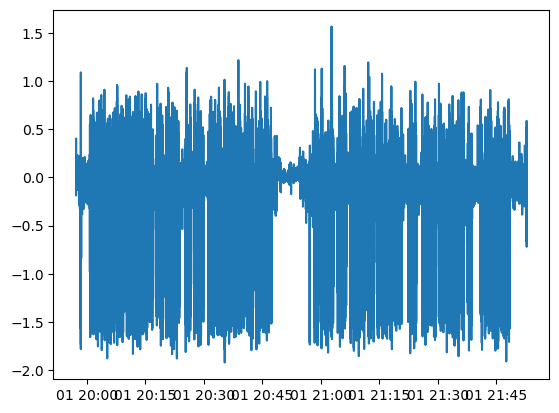

In [ ]:
plt.plot("timestamp", "diff", data=data)

In [ ]:
p_df["acc_z"].describe()

count    69247.000000
mean         0.368759
std          0.257309
min         -3.928821
25%          0.201867
50%          0.312719
75%          0.516919
max          5.207701
Name: acc_z, dtype: float64

In [ ]:
p_df["acc_z_filt"].describe()

count    69234.000000
mean         0.000035
std          0.221424
min         -4.236542
25%         -0.124902
50%         -0.017513
75%          0.093548
max          4.511563
Name: acc_z_filt, dtype: float64

In [ ]:
dd = make_data_dict(directory="data/raw/Catapult_RAW", preprocess_data=True)

2026-03-13 14:08:51.397 | INFO     | src.dataset:make_data_dict:874 - Processing file Game_1_hyökkääjä_JM_Catapult-Export-1770541727119.csv...
15
                 x            y        speed   playerload    accelrate
count  6922.000000  6922.000000  6922.000000  6918.000000  6918.000000
mean     -8.911455    -3.969130     0.858447     0.258687     1.167622
std       6.650926    22.249351     1.316594     0.409646     1.829676
min     -30.037324   -52.682586     0.000000     0.000036     0.000339
25%     -11.377774   -24.432503     0.000000     0.010311     0.036967
50%     -10.581330   -18.477081     0.000000     0.014148     0.063930
75%      -3.565036    16.339237     1.456123     0.319701     1.577532
max      11.377774    57.569086     9.070517     2.609534    12.613388
Setting start to NaN until index 95
Setting end to NaN from index 2907
Idle periods: 0
No idle periods detected.
2026-03-13 14:08:51.601 | INFO     | src.dataset:make_data_dict:883 - File <DirEntry 'Game_1_hyök

In [ ]:
data = concatenate_dfs(dd)

In [ ]:
data

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,turn_angle,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones
0,2025-08-20 20:03:32,-8.040294,32.373067,5.821047,1.230302,2.841073,0,1,hyökkääjä,JM,0.181345,True,2,393,0.001750,0.000000,0.001750,0.000000,1
1,2025-08-20 20:03:34,-3.640888,24.737910,6.091382,1.210012,4.967048,0,1,hyökkääjä,JM,-0.222366,True,2,393,0.003470,0.001750,0.003470,0.001750,1
2,2025-08-20 20:03:36,-2.882369,26.493996,2.867690,1.104330,3.783115,0,1,hyökkääjä,JM,2.211123,True,2,393,0.005041,0.003470,0.005041,0.003470,1
3,2025-08-20 20:03:38,-1.137777,32.831177,3.966365,1.143745,4.860939,0,1,hyökkääjä,JM,0.139091,True,2,393,0.006668,0.005041,0.006668,0.005041,1
4,2025-08-20 20:03:40,0.986074,29.777114,3.063802,1.237770,6.804991,0,1,hyökkääjä,JM,-2.265308,True,2,393,0.008428,0.006668,0.008428,0.006668,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98188,2025-05-16 21:19:22,-14.263045,-13.132471,3.188359,1.212202,5.118909,41,6,toppari,AA,0.452429,True,4,574,0.996054,0.995124,0.996054,0.995124,1
98189,2025-05-16 21:19:24,-14.604447,-12.292603,1.846126,0.962632,4.046461,41,6,toppari,AA,2.303566,True,4,574,0.996793,0.996054,0.996793,0.996054,1
98190,2025-05-16 21:19:26,-16.766664,-12.674361,2.508909,1.127886,5.507836,41,6,toppari,AA,1.359460,True,4,574,0.997658,0.996793,0.997658,0.996793,1
98191,2025-05-16 21:19:28,-20.408293,-3.359469,5.946825,1.735455,3.863005,41,6,toppari,AA,-1.372876,True,4,574,0.998990,0.997658,0.998990,0.997658,1


In [ ]:
data.groupby("player")["track_id"].unique()

player
AA           [4, 23, 41]
AY                  [25]
BP                  [15]
EB          [12, 18, 34]
EP          [10, 22, 30]
ET                  [13]
JM                   [0]
JN                   [5]
KL                  [21]
LT               [9, 36]
ML              [20, 27]
NN                   [1]
NR               [7, 28]
OG      [11, 19, 26, 39]
OH          [14, 29, 35]
OK          [24, 33, 38]
OKe                 [32]
OKes                [37]
OS                  [17]
PB                  [31]
RM               [6, 40]
SS            [2, 8, 16]
ST                   [3]
Name: track_id, dtype: object

C:\Users\jussi\AppData\Local\Temp\ipykernel_31472\1397974039.py:1: RuntimeWarning: Second argument 'y' is ambiguous: could be a format string but is in 'data'; using as data.  If it was intended as data, set the format string to an empty string to suppress this warning.  If it was intended as a format string, explicitly pass the x-values as well.  Alternatively, rename the entry in 'data'.
  plt.plot("x", "y" ,data=data[data["track_id"] == 30][500:550])


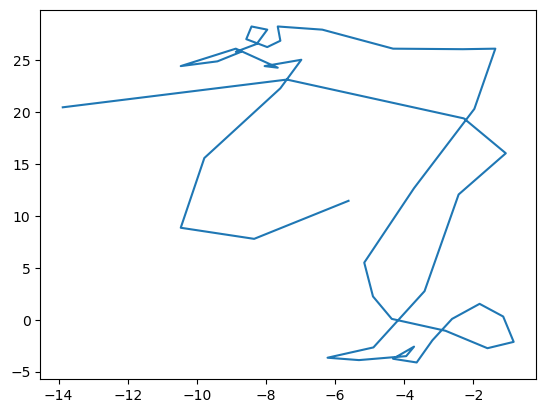

In [ ]:
plt.plot("x", "y" ,data=data[data["track_id"] == 30][500:550])

In [ ]:
(data.groupby("track_id").count()["speed"]/60).describe()

count     42.000000
mean      83.990476
std       19.479162
min       31.550000
25%       74.479167
50%       92.916667
75%       95.804167
max      108.816667
Name: speed, dtype: float64

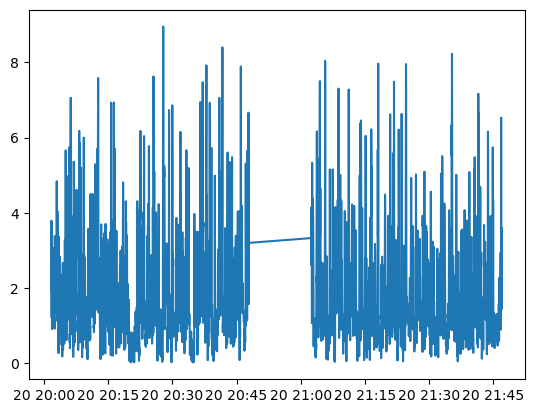

In [ ]:
plt.plot("timestamp", "speed", data=data[data["track_id"] == 5])

In [ ]:
data.groupby("track_id").count()

,timestamp,x,y,speed,playerload,accelrate,game,position,player,turn_angle,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones
track_id,,,,,,,,,,,,,,,,,,
0,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810,2810
1,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674,5674
2,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561,5561
3,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848,5848
4,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864,5864
5,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446,5446
6,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893,1893
7,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701,5701
8,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447,3447


<Axes: >

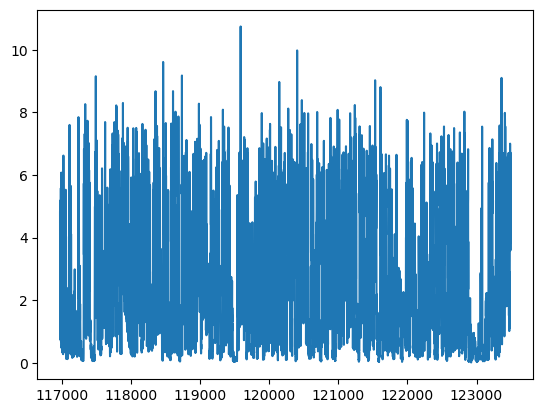

In [ ]:
data[data["track_id"] == 24]["accelrate"].plot()

Fitted von Mises parameters: kappa=1.960, loc=0.012


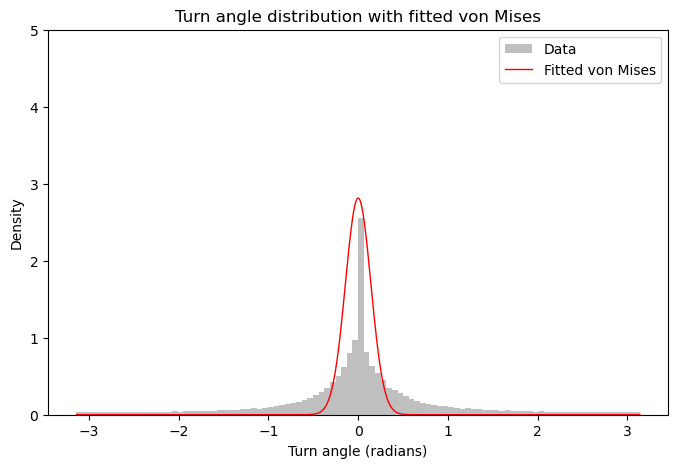

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import vonmises

# Load data
data = pd.read_csv("data/processed/soccerdata_processed.csv")

# Make sure turn_angle is in radians
turn_angles = data["turn_angle"].dropna()  # convert if in degrees, drop NaN

# Fit a von Mises distribution
kappa, loc, scale = vonmises.fit(turn_angles, fscale=1)  
# fscale=1 keeps the scale at 1, standard for angles in radians

print(f"Fitted von Mises parameters: kappa={kappa:.3f}, loc={loc:.3f}")

# Plot histogram
plt.figure(figsize=(8,5))
counts, bins, _ = plt.hist(turn_angles, bins=100, density=True, alpha=0.5, color='gray', label='Data')

# Plot fitted von Mises PDF
x = np.linspace(-np.pi, np.pi, 1000)  # full angular range
pdf = vonmises.pdf(x, 50, loc=0, scale=scale)
plt.plot(x, pdf, 'r-', lw=1, label='Fitted von Mises')

plt.xlabel("Turn angle (radians)")
plt.ylabel("Density")
plt.ylim((0,5))
plt.title("Turn angle distribution with fitted von Mises")
plt.legend()
plt.show()

In [6]:
data.groupby(["player", "track_id"]).count()

timestamp     x     y  speed  playerload  accelrate  game  \
player track_id                                                              
AA     4              2883  2883  2883   2883        2883       2883  2883   
       23             2934  2934  2934   2934        2934       2934  2934   
       41             1973  1973  1973   1973        1973       1973  1973   
AY     25             2159  2159  2159   2159        2159       2159  2159   
BP     15             2658  2658  2658   2658        2658       2658  2658   
EB     12             2104  2104  2104   2104        2104       2104  2104   
       18              782   782   782    782         782        782   782   
       34             2850  2850  2850   2850        2850       2850  2850   
EP     10             2457  2457  2457   2457        2457       2457  2457   
       22             2148  2148  2148   2148        2148       2148  2148   
       30             2777  2777  2777   2777        2777       2777  2777   
ET     13             1028  1028  1028   1028        1028       1028  1028   
JM     0              1134  1134  1134   1134        1134       1134  1134   
JN     5              2335  2335  2335   2335        2335       2335  2335   
KL     21             2851  2851  2851   2851        2851       2851  2851   
LT     9              2705  2705  2705   2705        2705       2705  2705   
       36             1864  1864  1864   1864        1864       1864  1864   
ML     20             2430  2430  2430   2430        2430       2430  2430   
       27             2510  2510  2510   2510        2510       2510  2510   
NN     1              2767  2767  2767   2767        2767       2767  2767   
NR     7              2806  2806  2806   2806        2806       2806  2806   
       28             2635  2635  2635   2635        2635       2635  2635   
OG     11             2506  2506  2506   2506        2506       2506  2506   
       19             2490  2490  2490   2490        2490       2490  2490   
       26             2823  2823  2823   2823        2823       2823  2823   
       39             2803  2803  2803   2803        2803       2803  2803   
OH     14             1912  1912  1912   1912        1912       1912  1912   
       29             1262  1262  1262   1262        1262       1262  1262   
       35             2325  2325  2325   2325        2325       2325  2325   
OK     24             3006  3006  3006   3006        3006       3006  3006   
       33             2430  2430  2430   2430        2430       2430  2430   
       38             2751  2751  2751   2751        2751       2751  2751   
OKe    32             2829  2829  2829   2829        2829       2829  2829   
OKes   37             2593  2593  2593   2593        2593       2593  2593   
OS     17             1921  1921  1921   1921        1921       1921  1921   
PB     31             2859  2859  2859   2859        2859       2859  2859   
RM     6               938   938   938    938         938        938   938   
       40             1818  1818  1818   1818        1818       1818  1818   
SS     2              2672  2672  2672   2672        2672       2672  2672   
       8              1687  1687  1687   1687        1687       1687  1687   
       16             2881  2881  2881   2881        2881       2881  2881   
ST     3              2921  2921  2921   2921        2921       2921  2921   

                 position  turn_angle  is_valid  segment_id  segment_length  \
player track_id                                                               
AA     4             2883        2883      2883        2883            2883   
       23            2934        2934      2934        2934            2934   
       41            1973        1973      1973        1973            1973   
AY     25            2159        2159      2159        2159            2159   
BP     15            2658        2658      2658        2658            2658   
EB     12            2104      

In [5]:
data

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
0,2025-08-20 20:03:32,-10.516856,35.209528,5.821047,1.230302,5.682147,0,1,hyökkääjä,JM,...,True,2,393,0.001750,0.000000,0.001750,0.000000,1,0,0
1,2025-08-20 20:03:34,-5.618724,28.429508,6.091382,1.210012,9.934096,0,1,hyökkääjä,JM,...,True,2,393,0.003470,0.001750,0.003470,0.001750,1,0,0
2,2025-08-20 20:03:36,-2.850132,24.363787,2.867690,1.104330,7.566231,0,1,hyökkääjä,JM,...,True,2,393,0.005041,0.003470,0.005041,0.003470,1,0,0
3,2025-08-20 20:03:38,-2.243318,30.288669,3.966365,1.143745,9.721877,0,1,hyökkääjä,JM,...,True,2,393,0.006668,0.005041,0.006668,0.005041,1,0,0
4,2025-08-20 20:03:40,0.193422,31.968404,3.063802,1.237770,13.609982,0,1,hyökkääjä,JM,...,True,2,393,0.008428,0.006668,0.008428,0.006668,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98212,2025-05-16 21:19:22,-15.530028,-12.651456,3.188359,1.212202,10.237819,41,6,toppari,AA,...,True,4,574,0.996054,0.995124,0.996054,0.995124,1,4,4
98213,2025-05-16 21:19:24,-14.071480,-12.212434,1.846126,0.962632,8.092923,41,6,toppari,AA,...,True,4,574,0.996793,0.996054,0.996793,0.996054,1,4,4
98214,2025-05-16 21:19:26,-15.630552,-12.991220,2.508909,1.127886,11.015672,41,6,toppari,AA,...,True,4,574,0.997658,0.996793,0.997658,0.996793,1,4,4
98215,2025-05-16 21:19:28,-18.651965,-8.642998,5.946825,1.735455,7.726011,41,6,toppari,AA,...,True,4,574,0.998990,0.997658,0.998990,0.997658,1,4,4


In [5]:
data["track_id"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41])

In [3]:
data.shape

(98217, 21)

In [5]:
data.shape[0]*2/60

3273.9

In [6]:
data["player"].unique()

array(['JM', 'NN', 'SS', 'ST', 'AA', 'JN', 'RM', 'NR', 'LT', 'EP', 'OG',
       'EB', 'ET', 'OH', 'BP', 'OS', 'ML', 'KL', 'OK', 'AY', 'PB', 'OKe',
       'OKes'], dtype=object)

In [10]:
ps = ['JM', 'NN', 'SS', 'ST']
data[data["player"].isin(ps)]

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
0,2025-08-20 20:03:32,-10.516856,35.209528,5.821047,1.230302,5.682147,0,1,hyökkääjä,JM,...,True,2,393,0.001750,0.000000,0.001750,0.000000,1,0,0
1,2025-08-20 20:03:34,-5.618724,28.429508,6.091382,1.210012,9.934096,0,1,hyökkääjä,JM,...,True,2,393,0.003470,0.001750,0.003470,0.001750,1,0,0
2,2025-08-20 20:03:36,-2.850132,24.363787,2.867690,1.104330,7.566231,0,1,hyökkääjä,JM,...,True,2,393,0.005041,0.003470,0.005041,0.003470,1,0,0
3,2025-08-20 20:03:38,-2.243318,30.288669,3.966365,1.143745,9.721877,0,1,hyökkääjä,JM,...,True,2,393,0.006668,0.005041,0.006668,0.005041,1,0,0
4,2025-08-20 20:03:40,0.193422,31.968404,3.063802,1.237770,13.609982,0,1,hyökkääjä,JM,...,True,2,393,0.008428,0.006668,0.008428,0.006668,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38389,2025-08-14 22:05:00,4.574182,87.407281,3.915920,1.425593,12.514658,16,3,keskikenttä,SS,...,True,4,1443,0.998035,0.997311,0.998035,0.997311,1,2,1
38390,2025-08-14 22:05:02,4.443111,82.161928,1.876237,0.714507,4.824352,16,3,keskikenttä,SS,...,True,4,1443,0.998398,0.998035,0.998398,0.998035,1,2,1
38391,2025-08-14 22:05:04,5.801309,80.947938,2.537020,0.778267,6.284947,16,3,keskikenttä,SS,...,True,4,1443,0.998794,0.998398,0.998794,0.998398,1,2,1
38392,2025-08-14 22:05:06,7.446343,74.969610,4.387591,1.167075,9.633596,16,3,keskikenttä,SS,...,True,4,1443,0.999386,0.998794,0.999386,0.998794,1,2,1


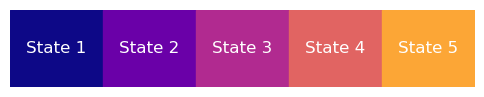

In [43]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

# Your setup
continuous_cmap = "plasma"
cmap = matplotlib.colors.ListedColormap(
    plt.get_cmap(continuous_cmap)(np.linspace(0,1,6)), N=5
)

# Example states 1..6
states = np.arange(1, 6)

# Plot colored rectangles for each state
fig, ax = plt.subplots(figsize=(6, 1))
for i, s in enumerate(states):
    ax.add_patch(
        plt.Rectangle((i, 0), 1, 1, color=cmap(s-1))
    )
    ax.text(i + 0.5, 0.5, f"State {s}", ha="center", va="center", color="white", fontsize=12)

ax.set_xlim(0, len(states))
ax.set_ylim(0, 1)
ax.axis("off")
plt.show()

In [ ]:
data

In [9]:
data["turn_angle"].describe()

count    98217.000000
mean         0.009368
std          0.961164
min         -3.141593
25%         -0.273449
50%          0.000000
75%          0.301491
max          3.140916
Name: turn_angle, dtype: float64

In [61]:
data.loc[data["speed"] <= 0.5, "turn_angle"] = 0

In [62]:
data[np.isclose(np.abs(data["turn_angle"]), np.pi/2, rtol=0.01)]["speed"].describe()

count    710.000000
mean       1.229199
std        0.850530
min        0.500004
25%        0.654561
50%        0.910118
75%        1.415178
max        4.804927
Name: speed, dtype: float64

<Axes: >

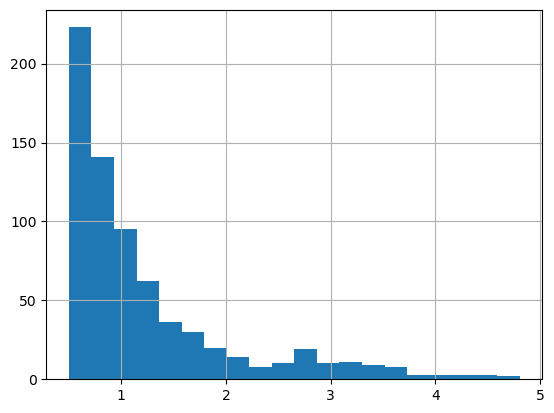

In [63]:
data[np.isclose(np.abs(data["turn_angle"]), np.pi/2, rtol=0.01)]["speed"].hist(bins=20)

In [14]:
data = pd.read_csv("data/processed/soccerdata_processed.csv")

In [28]:
data[(data["player"] == "AA") & (data["track_id"].isin([41,23, 4]))]

,timestamp,x,y,speed,playerload,accelrate,track_id,game,position,player,...,is_valid,segment_id,segment_length,playerload_cumulative,playerload_cumulative_t-1,accelrate_cumulative,accelrate_cumulative_lagged,ones,player_id,position_id
9494,2025-08-20 20:02:04,-6.068156,8.245970,2.260018,1.003639,3.934697,4,1,laitapakki,AA,...,True,2,1407,0.000479,0.000000,0.000479,0.000000,1,4,2
9495,2025-08-20 20:02:06,-4.626969,7.940564,1.922904,0.992850,5.124561,4,1,laitapakki,AA,...,True,2,1407,0.000953,0.000479,0.000953,0.000479,1,4,2
9496,2025-08-20 20:02:08,-5.992304,4.886501,2.222796,1.103215,6.133195,4,1,laitapakki,AA,...,True,2,1407,0.001479,0.000953,0.001479,0.000953,1,4,2
9497,2025-08-20 20:02:10,-2.427262,10.918275,4.669148,1.007078,3.402530,4,1,laitapakki,AA,...,True,2,1407,0.001960,0.001479,0.001960,0.001479,1,4,2
9498,2025-08-20 20:02:12,0.075852,14.659502,3.754586,1.206177,5.288327,4,1,laitapakki,AA,...,True,2,1407,0.002535,0.001960,0.002535,0.001960,1,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98188,2025-05-16 21:19:22,-14.263045,-13.132471,3.188359,1.212202,5.118909,41,6,toppari,AA,...,True,4,574,0.996054,0.995124,0.996054,0.995124,1,4,4
98189,2025-05-16 21:19:24,-14.604447,-12.292603,1.846126,0.962632,4.046461,41,6,toppari,AA,...,True,4,574,0.996793,0.996054,0.996793,0.996054,1,4,4
98190,2025-05-16 21:19:26,-16.766664,-12.674361,2.508909,1.127886,5.507836,41,6,toppari,AA,...,True,4,574,0.997658,0.996793,0.997658,0.996793,1,4,4
98191,2025-05-16 21:19:28,-20.408293,-3.359469,5.946825,1.735455,3.863005,41,6,toppari,AA,...,True,4,574,0.998990,0.997658,0.998990,0.997658,1,4,4


In [31]:
data[(data["player"] == "AA")].isna().sum()

timestamp                      0
x                              0
y                              0
speed                          0
playerload                     0
accelrate                      0
track_id                       0
game                           0
position                       0
player                         0
turn_angle                     0
is_valid                       0
segment_id                     0
segment_length                 0
playerload_cumulative          0
playerload_cumulative_t-1      0
accelrate_cumulative           0
accelrate_cumulative_lagged    0
ones                           0
player_id                      0
position_id                    0
dtype: int64

In [44]:
summary = pd.read_csv("data/summary/summarydata.csv")

In [54]:
summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1281 entries, 0 to 1280
Columns: 107 entries, Team to Zone 5
dtypes: float64(71), int64(30), object(6)
memory usage: 1.0+ MB
